<center><h1>Chen_Jessica_HW5</h1></center>
<br>
<br>

Name: Jessica Chen
<br>
Github Username: jc6006 
<br>
USC ID: 9760667304

## 1. Decision Trees as Interpretable Models

Import packages

In [25]:
import pandas as pd, numpy as np, seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error as mse
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [26]:
cols=['temp','nausea','lumbar_pain','urine_pushing','micturition_pain','urethra_burning','d1_bladder','d2_nephritis']
df=pd.read_csv("..\data\diagnosis.data",sep='\t',names=cols,encoding='utf-16',decimal=',')
df=df.replace({'yes':1,'no':0})
x=df[cols[:6]]
y=((df.d1_bladder*2) + df.d2_nephritis).astype(int)
#df

### (b) Build a decision tree

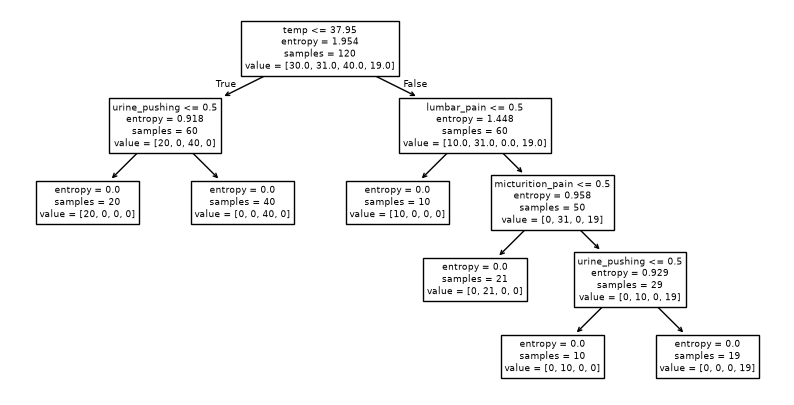

In [27]:
dt=DecisionTreeClassifier(criterion='entropy',random_state=0).fit(x,y)
plt.figure(figsize=(10,5))
plot_tree(dt,feature_names=x.columns)
plt.show()

### (c) Convert the decision rules

In [28]:
names_map={0:'neither',1:'nephritis',2:'bladder inflammation',3:'both'}
def tree_to_code(model,names):
    t,rules = model.tree_,[]
    def rec(n, conds):
        if t.feature[n]==-2:
            label=names_map[model.classes_[t.value[n].argmax()]]
            rules.append("if " + " and ".join(conds) + f" then diagnosis = {label}")
            return
        f,th=names[t.feature[n]],t.threshold[n]
        rec(t.children_left[n],conds+[f"{f} <= {th:.2f}"])
        rec(t.children_right[n],conds+[f"{f} > {th:.2f}"])
    rec(0,[])
    return rules

### (d) Minimal decision tree and a set of decision rules with high interpretability

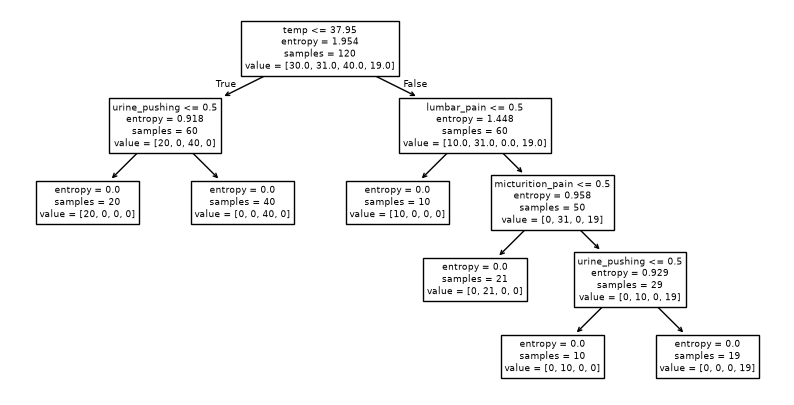

if temp <= 37.95 and urine_pushing <= 0.50 then diagnosis = neither
if temp <= 37.95 and urine_pushing > 0.50 then diagnosis = bladder inflammation
if temp > 37.95 and lumbar_pain <= 0.50 then diagnosis = neither
if temp > 37.95 and lumbar_pain > 0.50 and micturition_pain <= 0.50 then diagnosis = nephritis
if temp > 37.95 and lumbar_pain > 0.50 and micturition_pain > 0.50 and urine_pushing <= 0.50 then diagnosis = nephritis
if temp > 37.95 and lumbar_pain > 0.50 and micturition_pain > 0.50 and urine_pushing > 0.50 then diagnosis = both


In [29]:
alphas=dt.cost_complexity_pruning_path(x,y).ccp_alphas
scores=[cross_val_score(DecisionTreeClassifier(criterion='entropy',ccp_alpha=a,random_state=0),x,y,cv=5).mean() for a in alphas]
best=alphas[np.argmax(scores)]
pruned=DecisionTreeClassifier(criterion='entropy',ccp_alpha=best,random_state=0).fit(x, y)
plt.figure(figsize=(10, 5));plot_tree(pruned,feature_names=x.columns);plt.show()
tree_to_code(pruned,list(x.columns))
print("\n".join(tree_to_code(dt, list(x.columns))))

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [30]:
df=pd.read_csv("..\data\communities.data",header=None,na_values='?')
x,y = df.iloc[:,5:-1], df.iloc[:,-1]
xtr,xte,ytr,yte=x.iloc[:1495],x.iloc[1495:],y.iloc[:1495],y.iloc[1495:]
#df

### (a) Missing Values

In [31]:
imp=SimpleImputer(strategy='mean').fit(xtr)
xtr=pd.DataFrame(imp.transform(xtr),columns=X.columns)
xte=pd.DataFrame(imp.transform(xte),columns=X.columns)

### (c) Plot a correlation matrix

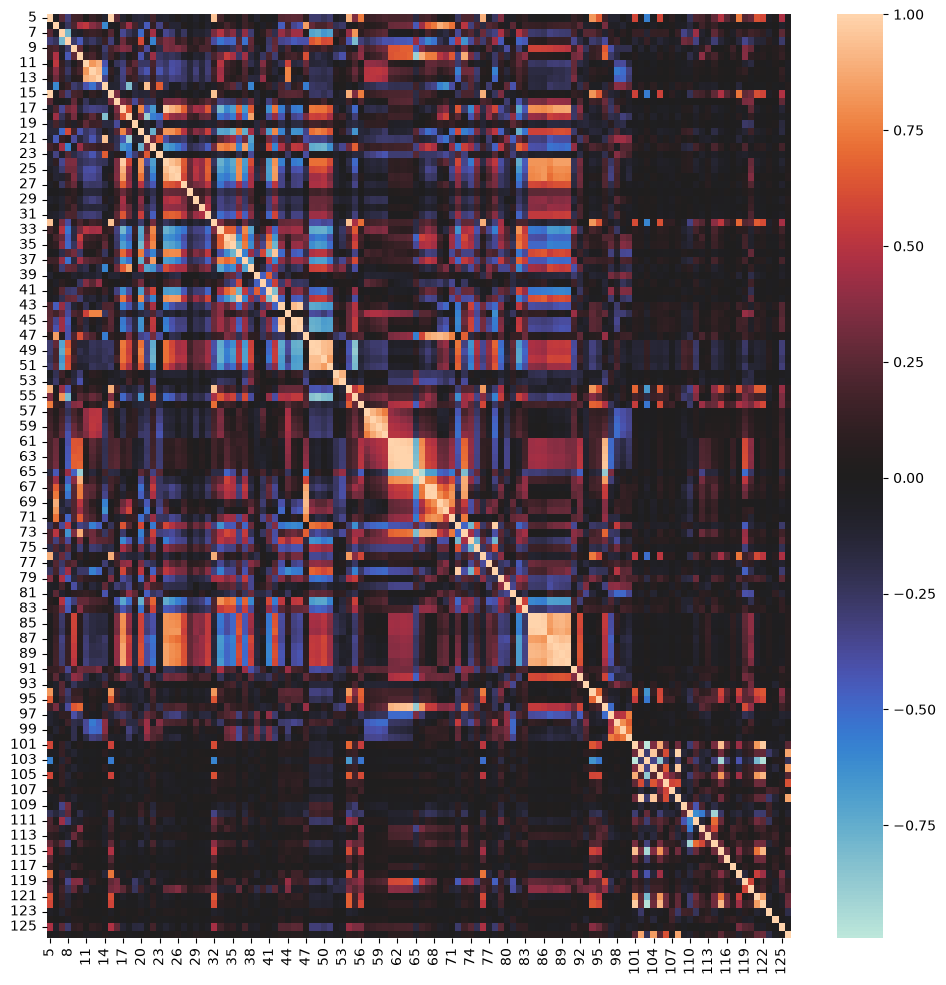

In [32]:
plt.figure(figsize=(12, 12))
sns.heatmap(xtr.corr(),center=0)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [33]:
cv=(xtr.std()/xtr.mean()).abs().sort_values(ascending=False)
print(cv)

95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
         ...   
116    0.144382
109    0.134853
110    0.122813
123    0.115739
103    0.064288
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

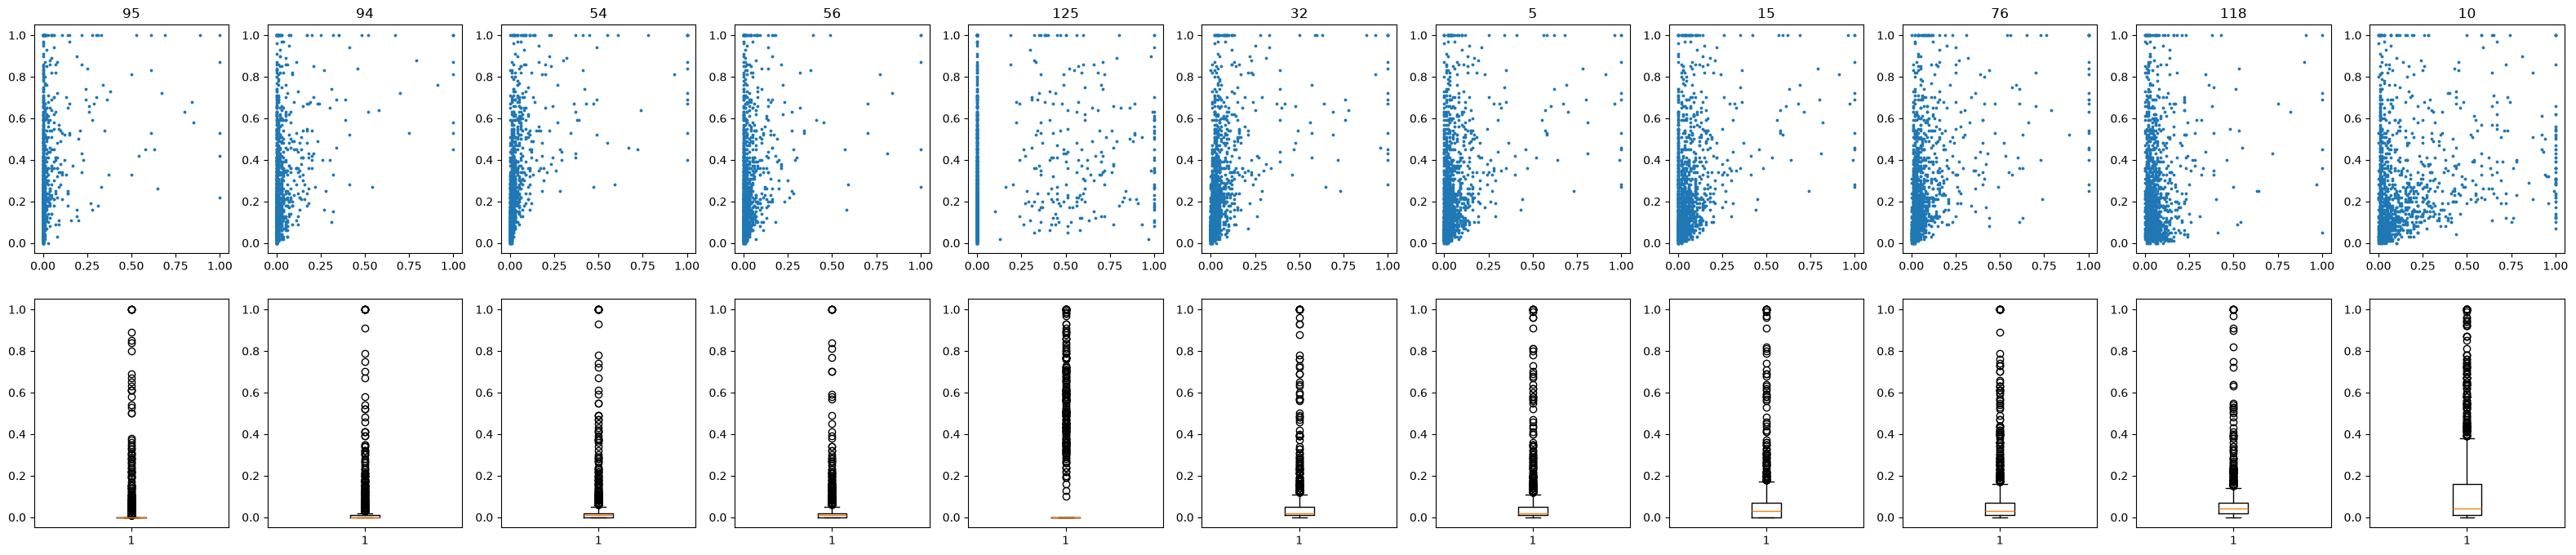

In [34]:
top=cv.index[:11]
fig,ax=plt.subplots(2,11,figsize=(40,8))
for i,c in enumerate(top):
    ax[0,i].scatter(xtr[c],ytr,s=3); ax[0,i].set_title(str(c))
    ax[1,i].boxplot(xtr[c])
plt.show()

### (f) Fit a linear model

In [35]:
print("linear model test MSE: ",mse(yte, LinearRegression().fit(xtr,ytr).predict(xte)))

linear model test MSE:  0.01814197113553011


### (g) Fit a ridge regression model

In [36]:
r=RidgeCV(alphas=np.logspace(-3,3,50),cv=5).fit(xtr,ytr)
print("lambda:",r.alpha_)
print("ridge model test MSE:",mse(yte,r.predict(xte)))

lambda: 2.023589647725158
ridge model test MSE: 0.017619653431557792


### (h) Fit a LASSO model

In [37]:
l = LassoCV(cv=5, max_iter=50000).fit(xtr,ytr)
print("--lasso model raw--")
print("lambda (CV):",l.alpha_)
print("test MSE:",mse(yte,l.predict(xte)))
print("selected features:", list(xtr.columns[l.coef_ != 0]))
print()
ls = make_pipeline(StandardScaler(),LassoCV(cv=5, max_iter=50000)).fit(xtr,ytr)
print("--lasso model standardized--")
print("lambda:", ls[-1].alpha_)
print("test MSE:",mse(yte, ls.predict(xte)))
print("selected features:",list(xtr.columns[ls[-1].coef_ != 0]))

--lasso model raw--
lambda (CV): 0.00011614723626829858
test MSE: 0.017758209216319678
selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 105, 107, 109, 111, 113, 115, 116, 117, 118, 119, 120, 123, 124, 125, 126]

--lasso model standardized--
lambda: 0.0007630833878262516
test MSE: 0.017805339276862273
selected features: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


### (i) Fit a PCR model

In [38]:
pcr = GridSearchCV(make_pipeline(PCA(), LinearRegression()),{'pca__n_components':range(1,xtr.shape[1] + 1)},cv=5,scoring='neg_mean_squared_error').fit(xtr, ytr)
print("PCR M:", pcr.best_params_['pca__n_components'])
print("PCR test MSE:", mse(yte, pcr.predict(xte)))

PCR M: 96
PCR test MSE: 0.01847177851616755


### (j) Fit a boosting tree

In [39]:
gb = GridSearchCV(XGBRegressor(random_state=0),{'reg_alpha': [0, 0.01, 0.1, 1, 10]},cv=5, scoring='neg_mean_squared_error').fit(xtr,ytr)
print("L1-penalized gradient boosting tree alpha:",gb.best_params_['reg_alpha'])
print("L1-penalized gradient boosting tree test MSE:",mse(yte, gb.predict(xte)))

L1-penalized gradient boosting tree alpha: 1
L1-penalized gradient boosting tree test MSE: 0.017747461401957192
